#  <span style="color:#C133FF"> Loading niftis after optimization - Creating figures </span> 


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import nibabel as nib
from pathlib import Path

In [2]:
import os, sys, importlib
parent_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(parent_dir)
print(parent_dir)

c:\Users\Admin\Documents\msc_project\Image-processing-strategies


In [3]:
import monkey_tools.extract_metric
importlib.reload(monkey_tools.extract_metric)

from monkey_tools.extract_metric import cnr_wm_gm # re-import updated function

In [ ]:
# Loading the simulated related data

initial_field_Hz_data = nib.load(r"R:\soothsayer\msc_data\chi_fitting\rosenberg_results\chi_027\mb_r1_solver_n_pad_constant_cropped\initial_field_demod_Hz.nii.gz").get_fdata()
fitted_dmod_field_Hz_data = nib.load(r"R:\soothsayer\msc_data\chi_fitting\rosenberg_results\chi_027\mb_r1_solver_n_pad_constant_cropped\fitted_field_demod_Hz.nii.gz").get_fdata()
vert_levels_data = nib.load(r"R:\soothsayer\msc_data\chi_fitting\chi_027\niftis\t1w\for_rosenberg\cord_levels_crop.nii.gz").get_fdata()


In [ ]:
# Loading the in-vivo related measured data - this should be already from 2 to 14
in_vivo_dmod_exp_field_Hz_df = pd.read_csv(r"R:\soothsayer\msc_data\chi_fitting\for_rosenberg_transfer\chi_027\measured\sub-16_clearswi_DEMOD_EXP_mean_per_level_1_15.csv")
in_vivo_dmod_inspp_field_Hz_df = pd.read_csv(r"R:\soothsayer\msc_data\chi_fitting\for_rosenberg_transfer\chi_027\measured\sub-16_clearswi_DEMOD_INSP_mean_per_level_1_15.csv")


In [6]:
in_vivo_dmod_exp_field_Hz_df

,dmod_B0_Hz
0,-88.529857
1,-129.258104
2,-129.820939
3,-77.540794
4,-17.659670
5,57.894648
6,94.147902
7,67.815051
8,47.684115
9,55.965864


In [7]:
in_vivo_dmod_inspp_field_Hz_df

,dmod_B0_Hz
0,-88.205801
1,-118.947455
2,-114.451920
3,-51.574333
4,23.997797
5,107.269381
6,137.513825
7,69.752120
8,24.329495
9,12.901285


In [8]:
demod_avg_respiration = (in_vivo_dmod_exp_field_Hz_df+ in_vivo_dmod_inspp_field_Hz_df )/2
demod_avg_respiration

,dmod_B0_Hz
0,-88.367829
1,-124.102780
2,-122.136430
3,-64.557563
4,3.169063
5,82.582015
6,115.830863
7,68.783586
8,36.006805
9,34.433574


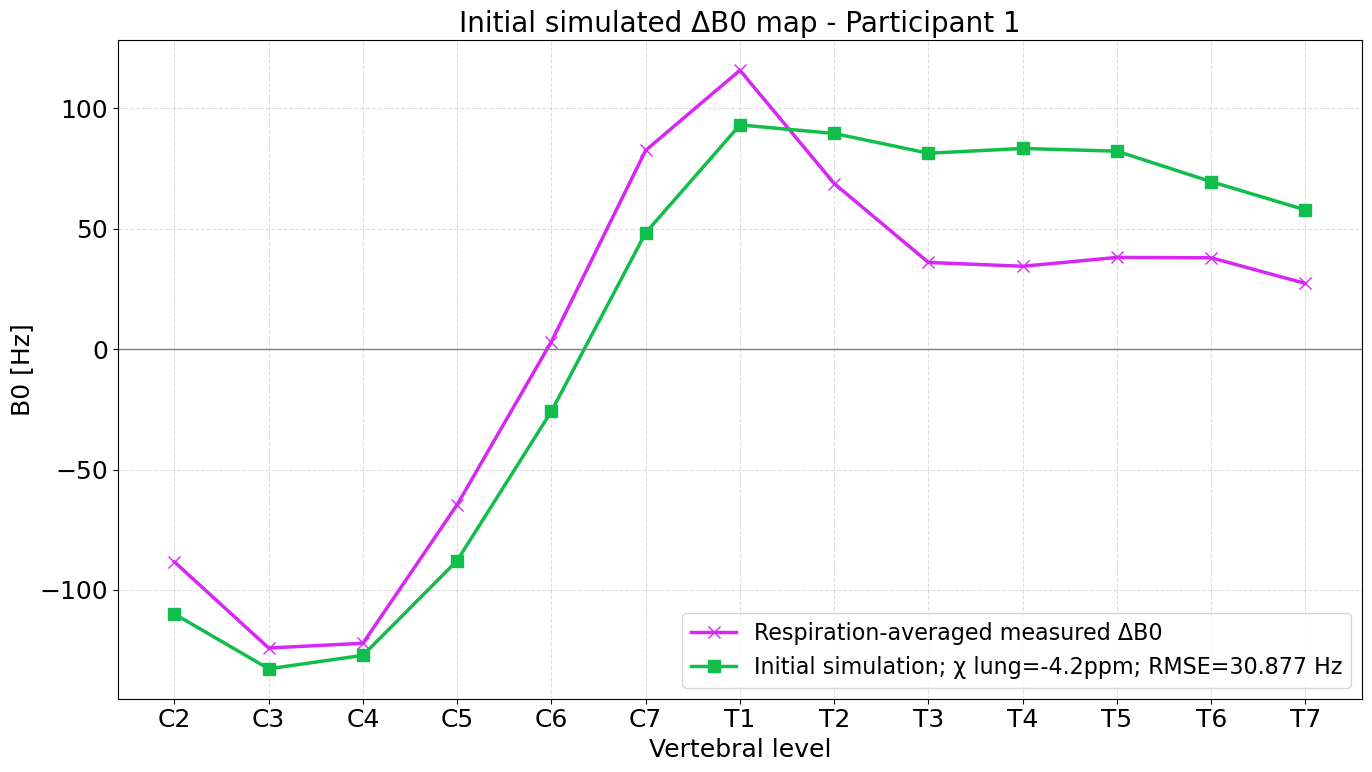

In [21]:

# Recreate average_lung_fit.png from saved optimization results
# No optimization or fieldmap simulation required!

results_dir = Path(r"R:\soothsayer\msc_data\chi_fitting\rosenberg_results\db0_033\mb_r1_solver_n_pad_constants_cropped")

fit_df = pd.read_csv(results_dir / "average_lung_fit.csv")

# Load profiles directly from CSV
levels = fit_df["VertebralLevel"]
measured = fit_df["MeasuredProfile_Hz"].to_numpy()
fitted = fit_df["FittedProfile_Hz"].to_numpy()

# Fitted parameters
chi = fit_df["FittedLungChi_ppm"].iloc[0]
rmse = fit_df["FitRMSE_Hz"].iloc[0]

# Initial simulation comparison
initial = fit_df["InitialProfile_Hz"].to_numpy()
initial_rmse = np.sqrt(np.mean((initial - measured)**2))

# --------------------------------------------------
# EDIT FIGURE LABELS HERE
# --------------------------------------------------
title = "Initial simulated ΔB0 map - Participant 1"
xlabel = "Vertebral level"
ylabel = "B0 [Hz]"

measured_label = "Respiration-averaged measured ΔB0"
fitted_label = f"Optimized χ lung={chi:.4f} ppm; RMSE={rmse:.3f} Hz"
initial_label = f"Initial simulation; χ lung=-4.2ppm; RMSE={initial_rmse:.3f} Hz"

# --------------------------------------------------
# PLOT
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 8))

ax.plot(levels, measured, "x-", color="#D627F5",
        label=measured_label)

#ax.plot(levels, fitted, "s--", color="#11BD4B", label=fitted_label)

ax.plot(levels, initial, "s-", color="#11BD4B",
        label=initial_label)

ax.axhline(0, color="gray", linewidth=1)

ax.set(
    xlabel=xlabel,
    ylabel=ylabel,
    title=title
)

ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()

fig.tight_layout()

# Save as a NEW file to preserve the original
fig.savefig(
    results_dir / "average_lung_fit_replot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.rcParams.update({
    "font.size": 16,        # Default font size
    "axes.titlesize": 20,   # Plot title
    "axes.labelsize": 18,   # X and Y axis labels
    "xtick.labelsize": 18,  # X-axis ticks
    "ytick.labelsize": 18,  # Y-axis ticks
    "legend.fontsize": 16,  # Legend
})

plt.rcParams.update({
    "lines.linewidth": 2.5,
    "lines.markersize": 9,
})

plt.show()


#  <span style="color:#C133FF"> Editing susceptibility map to create empty lung and only lung chi maps </span> 


In [11]:
# Select the niftis:
labels_img = nib.load(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sim\for_rosenberg\tissue_labels_crop.nii.gz")
labels_data = labels_img.get_fdata()
susceptibility_data = nib.load(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sim\for_rosenberg\susceptibility_ppm_crop.nii.gz").get_fdata()


In [12]:
# Now if labels == 12 
just_lung = susceptibility_data.copy()
just_lung[labels_data != 12] = 0

no_lungs = susceptibility_data.copy()
no_lungs[labels_data == 12] = 0

# Now save this new niftis
just_lung_img = nib.Nifti1Image(just_lung, affine=labels_img.affine)
no_lungs_img = nib.Nifti1Image(no_lungs, affine=labels_img.affine)

nib.save(just_lung_img, r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sim\for_rosenberg\susceptibility_ppm_crop_just_lung.nii.gz")
nib.save(no_lungs_img, r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sim\for_rosenberg\susceptibility_ppm_crop_no_lungs.nii.gz")